# Comparación de Métodos de Asignación de Hubs
Compara los dos métodos de asignación de hubs:
- **Método 1**: Basado en `hubs_id.xlsx` (asignación manual / geográfica)
- **Método 2**: Basado en clustering KMedoids (`final_results.csv`)

### Dimensiones de comparación
1. Cobertura de cargas (% con hub dentro de 50 millas)
2. Número de hubs y eficiencia (cargas por hub)
3. Solapamiento geográfico entre métodos
4. Cobertura por región
5. Ratio inbound/outbound por estado
6. Rate per mile
7. **Deadhead** (distancia carga → hub asignado)
8. **Conectividad** (flujos entre pares de hubs)
9. **Distancia promedio de cargas**

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import gc
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import folium
from math import radians, sin, cos, sqrt, atan2
import ast
import warnings
warnings.filterwarnings('ignore')

region5 = {
    'AL': 'SOUTHEAST', 'AR': 'SOUTHEAST', 'GA': 'SOUTHEAST', 'MS': 'SOUTHEAST',
    'VA': 'SOUTHEAST', 'KY': 'SOUTHEAST', 'TN': 'SOUTHEAST', 'FL': 'SOUTHEAST',
    'SC': 'SOUTHEAST', 'NC': 'SOUTHEAST', 'WV': 'SOUTHEAST', 'LA': 'SOUTHEAST',
    'AZ': 'SOUTHWEST', 'NM': 'SOUTHWEST', 'TX': 'SOUTHWEST', 'OK': 'SOUTHWEST',
    'IL': 'MIDWEST', 'IA': 'MIDWEST', 'NE': 'MIDWEST', 'SD': 'MIDWEST',
    'MO': 'MIDWEST', 'IN': 'MIDWEST', 'MN': 'MIDWEST', 'MI': 'MIDWEST',
    'WI': 'MIDWEST', 'KS': 'MIDWEST', 'ND': 'MIDWEST', 'OH': 'MIDWEST',
    'UT': 'WEST', 'NV': 'WEST', 'ID': 'WEST', 'WY': 'WEST',
    'CO': 'WEST', 'MT': 'WEST', 'WA': 'WEST', 'OR': 'WEST', 'CA': 'WEST',
    'MD': 'NORTHEAST', 'ME': 'NORTHEAST', 'NH': 'NORTHEAST', 'VT': 'NORTHEAST',
    'MA': 'NORTHEAST', 'PA': 'NORTHEAST', 'NY': 'NORTHEAST', 'RI': 'NORTHEAST',
    'CT': 'NORTHEAST', 'NJ': 'NORTHEAST', 'DE': 'NORTHEAST'
}

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlon, dlat = lon2-lon1, lat2-lat1
    a = sin(dlat/2)**2 + cos(lat1)*cos(lat2)*sin(dlon/2)**2
    return 3958.8 * 2 * atan2(sqrt(a), sqrt(1-a))

def haversine_matrix(lats_q, lngs_q, hub_lats, hub_lngs):
    lat_q = np.radians(np.asarray(lats_q, dtype=np.float64))[:, None]
    lng_q = np.radians(np.asarray(lngs_q, dtype=np.float64))[:, None]
    lat_h = np.radians(hub_lats)[None, :]
    lng_h = np.radians(hub_lngs)[None, :]
    dlat = lat_h - lat_q
    dlng = lng_h - lng_q
    a = np.sin(dlat/2)**2 + np.cos(lat_q) * np.cos(lat_h) * np.sin(dlng/2)**2
    return 3958.8 * 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

## 1. Cargar datos de ambos métodos

In [2]:
# Hubs M1
hubs_m1 = pd.read_excel('../utils/hubs_id.xlsx')
print(f'Hubs M1: {len(hubs_m1)}')

# Hubs M2
hubs_m2_raw = pd.read_csv('../5. merge dbscan/results/final_results.csv')
hubs_m2 = hubs_m2_raw.dropna(subset=['lat', 'lng']).copy()
hubs_m2_named = hubs_m2[hubs_m2['new_name'].notna()]
print(f'Hubs M2 total: {len(hubs_m2)} | con nombre: {len(hubs_m2_named)}')

# Cargas M1 — polars lazy scan con columnas clave
COLS_FULL = ['ID', 'HubOrigin', 'HubDestination',
             'LatOrigin', 'LngOrigin', 'LatDestination', 'LngDestination',
             'StateOrigin', 'StateDestination', 'RatePerMile', 'Distance']
_probe_full = pl.read_parquet('../2. cleaning_loads/parquetloadsfull.parquet', n_rows=1)
df_full = (
    pl.scan_parquet('../2. cleaning_loads/parquetloadsfull.parquet')
    .select([c for c in COLS_FULL if c in _probe_full.columns])
    .collect()
    .to_pandas()
)

# Cargas M2 con asignación — polars lazy scan
COLS_M2 = ['ID', 'near_hub_m2', 'near_hub_name_m2', 'tier_hub_m2',
           'hubs_50m_m2', 'near_hub_dest_m2', 'near_hub_name_dest_m2']
_probe_m2 = pl.read_parquet('hubs_assign_m2.parquet', n_rows=1)
df_m2 = (
    pl.scan_parquet('hubs_assign_m2.parquet')
    .select([c for c in COLS_M2 if c in _probe_m2.columns])
    .collect()
    .to_pandas()
)

# Merge unificado por ID
df = df_full.merge(df_m2, on='ID', how='left')
print(f'Cargas totales: {len(df):,}')

del df_full, df_m2
gc.collect()

# Tipos numéricos + limpiar inf/nan
for col in ['Distance', 'RatePerMile']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').replace([np.inf, -np.inf], np.nan)
for col in ['LatOrigin', 'LngOrigin', 'LatDestination', 'LngDestination']:
    if col in df.columns:
        df[col] = df[col].astype('float32')

Hubs M1: 194
Hubs M2 total: 192 | con nombre: 88
Cargas totales: 57,573,489


In [ ]:
df['hub_m1'] = df['HubOrigin'].notna()
df['hub_m2'] = df['near_hub_m2'].notna()

# ── FIX BUG 1: hubs_50m_m2 es una lista de hub_ids, no un número.
# pd.to_numeric convierte listas a NaN → fillna(0) → siempre False.
# Corrección: medir la longitud de la lista.
import ast

def _list_len(x):
    if isinstance(x, list):
        return len(x)
    if isinstance(x, str):
        try:
            return len(ast.literal_eval(x))
        except Exception:
            return 0
    return 0

if 'hubs_50m_m2' in df.columns:
    df['en_radio_50_m2'] = df['hubs_50m_m2'].apply(_list_len) > 0
else:
    df['en_radio_50_m2'] = df['hub_m2']

# ── FIX BUG 2: la columna hubs_50m no existe en parquetloadsfull.parquet.
# El fallback anterior (hub_m1 = HubOrigin.notna()) ignora la restricción
# de 50 millas: reportaba 93.2% = cargas con cualquier hub, no hub <= 50mi.
# Corrección: calcular vectorialmente la distancia al hub M1 asignado.
_hub_lat_m1 = (
    hubs_m1.dropna(subset=['lat', 'lng'])
    .drop_duplicates(subset=['new_name'])
    .set_index('new_name')['lat']
)
_hub_lng_m1 = (
    hubs_m1.dropna(subset=['lat', 'lng'])
    .drop_duplicates(subset=['new_name'])
    .set_index('new_name')['lng']
)
_mask_m1 = df['HubOrigin'].notna() & df['LatOrigin'].notna()
_lat_o = df.loc[_mask_m1, 'LatOrigin'].astype(float).values
_lng_o = df.loc[_mask_m1, 'LngOrigin'].astype(float).values
_lat_h = _hub_lat_m1.reindex(df.loc[_mask_m1, 'HubOrigin']).values
_lng_h = _hub_lng_m1.reindex(df.loc[_mask_m1, 'HubOrigin']).values
_dlat = np.radians(_lat_h - _lat_o)
_dlng = np.radians(_lng_h - _lng_o)
_a = (np.sin(_dlat/2)**2
      + np.cos(np.radians(_lat_o)) * np.cos(np.radians(_lat_h)) * np.sin(_dlng/2)**2)
_dist_m1 = 3958.8 * 2 * np.arctan2(np.sqrt(_a), np.sqrt(1 - _a))
df['en_radio_50_m1'] = False
df.loc[_mask_m1, 'en_radio_50_m1'] = _dist_m1 <= 50
del _lat_o, _lng_o, _lat_h, _lng_h, _dlat, _dlng, _a, _dist_m1, _mask_m1
del _hub_lat_m1, _hub_lng_m1

summary = pd.DataFrame({
    'Métrica': [
        'Cargas con hub asignado',
        'Cargas con hub en 50 millas',
        'Número de hubs',
    ],
    'Método 1': [
        f"{100*df['hub_m1'].mean():.1f}%",
        f"{100*df['en_radio_50_m1'].mean():.1f}%",
        str(len(hubs_m1)),
    ],
    'Método 2': [
        f"{100*df['hub_m2'].mean():.1f}%",
        f"{100*df['en_radio_50_m2'].mean():.1f}%",
        str(len(hubs_m2)),
    ]
})
print(summary.to_string(index=False))

## 3. Eficiencia: cargas por hub

In [4]:
cargas_m1 = df[df['hub_m1']].groupby('HubOrigin')['ID'].count()
cargas_m2 = df[df['hub_m2']].groupby('near_hub_m2')['ID'].count()

ef = pd.DataFrame({
    'Método': ['M1', 'M2'],
    'N hubs': [len(hubs_m1), len(hubs_m2)],
    'N hubs con nombre': [len(hubs_m1), len(hubs_m2_named)],
    'Cargas/hub (media)': [cargas_m1.mean(), cargas_m2.mean()],
    'Cargas/hub (mediana)': [cargas_m1.median(), cargas_m2.median()],
    'Cargas/hub (max)': [cargas_m1.max(), cargas_m2.max()],
    'Hubs activos (>0 cargas)': [len(cargas_m1[cargas_m1 > 0]), len(cargas_m2[cargas_m2 > 0])]
})
ef.set_index('Método')

,N hubs,N hubs con nombre,Cargas/hub (media),Cargas/hub (mediana),Cargas/hub (max),Hubs activos (>0 cargas)
Método,,,,,,
M1,194,194,177660.781457,90531.0,2012543,302
M2,192,88,559275.627451,461205.0,2267607,102


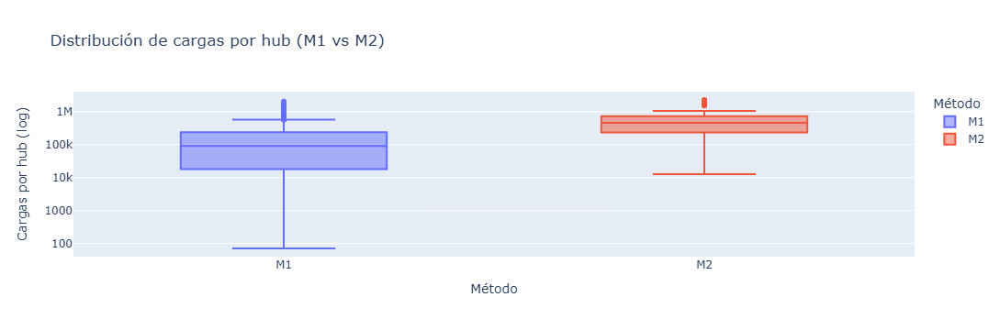

In [5]:
cargas_m1_df = cargas_m1.reset_index().rename(columns={'HubOrigin': 'hub', 'ID': 'cargas'})
cargas_m1_df['metodo'] = 'M1'
cargas_m2_df = cargas_m2.reset_index().rename(columns={'near_hub_m2': 'hub', 'ID': 'cargas'})
cargas_m2_df['metodo'] = 'M2'
cpc = pd.concat([cargas_m1_df, cargas_m2_df])

fig_box = px.box(
    cpc, x='metodo', y='cargas', color='metodo',
    log_y=True,
    title='Distribución de cargas por hub (M1 vs M2)',
    labels={'cargas': 'Cargas por hub (log)', 'metodo': 'Método'}
)
fig_box.show()

## 4. Solapamiento geográfico entre métodos

Hubs M2 con hub M1 en <= 50 millas: 131 / 192 (68.2%)


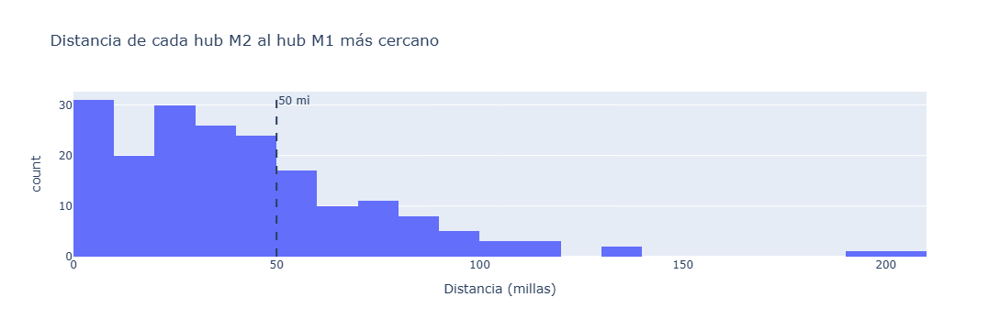

In [6]:
# Para cada hub M2, encontrar el hub M1 más cercano y la distancia — vectorizado
hubs_m2_coords = hubs_m2_raw.dropna(subset=['lat', 'lng']).copy()
hubs_m1_clean  = hubs_m1.dropna(subset=['lat', 'lng']).reset_index(drop=True)

dist_mat = haversine_matrix(
    hubs_m2_coords['lat'].values, hubs_m2_coords['lng'].values,
    hubs_m1_clean['lat'].values,  hubs_m1_clean['lng'].values
)
idx = dist_mat.argmin(axis=1)
hubs_m2_coords['nearest_m1'] = hubs_m1_clean['new_name'].values[idx]
hubs_m2_coords['dist_to_m1'] = dist_mat[np.arange(len(hubs_m2_coords)), idx]
del dist_mat

solapados = (hubs_m2_coords['dist_to_m1'] <= 50).sum()
total_m2  = len(hubs_m2_coords)
print(f'Hubs M2 con hub M1 en <= 50 millas: {solapados} / {total_m2} ({100*solapados/total_m2:.1f}%)')

fig_dist = px.histogram(
    hubs_m2_coords, x='dist_to_m1', nbins=40,
    title='Distancia de cada hub M2 al hub M1 más cercano',
    labels={'dist_to_m1': 'Distancia (millas)', 'count': 'N hubs M2'}
)
fig_dist.add_vline(x=50, line_dash='dash', annotation_text='50 mi')
fig_dist.show()

In [7]:
# Mapa dual: hubs M1 (azul) y M2 (rojo) superpuestos
m = folium.Map(location=[38.5, -96], zoom_start=4, tiles='OpenStreetMap')

for _, row in hubs_m1.dropna(subset=['lat', 'lng']).iterrows():
    folium.CircleMarker(
        [row['lat'], row['lng']], radius=5,
        color='blue', fill=True, fill_opacity=0.6,
        popup=f"M1: {row['new_name']}"
    ).add_to(m)

for _, row in hubs_m2_raw.dropna(subset=['lat', 'lng']).iterrows():
    tier_color = 'red' if row.get('Z') == 1.0 else ('orange' if pd.notna(row.get('new_name')) else 'green')
    folium.CircleMarker(
        [row['lat'], row['lng']], radius=4,
        color=tier_color, fill=True, fill_opacity=0.5,
        popup=f"M2: {row.get('new_name', 'Cluster ') or 'Cluster'} [{row.get('categoría','')}]"
    ).add_to(m)

legend_html = '''
<div style="position:fixed;bottom:30px;left:30px;z-index:1000;
            background:white;padding:10px;border:2px solid gray;font-size:12px">
<b>Método</b><br>
<span style="color:blue">●</span> M1 (hubs_id)<br>
<span style="color:red">●</span> M2 Primaria<br>
<span style="color:orange">●</span> M2 Secundaria<br>
<span style="color:green">●</span> M2 Terciario
</div>'''
m.get_root().html.add_child(folium.Element(legend_html))
m.save('map_comparacion_solapamiento.html')
print('✓ Mapa guardado: map_comparacion_solapamiento.html')

✓ Mapa guardado: map_comparacion_solapamiento.html


## 5. Comparación de cobertura por región

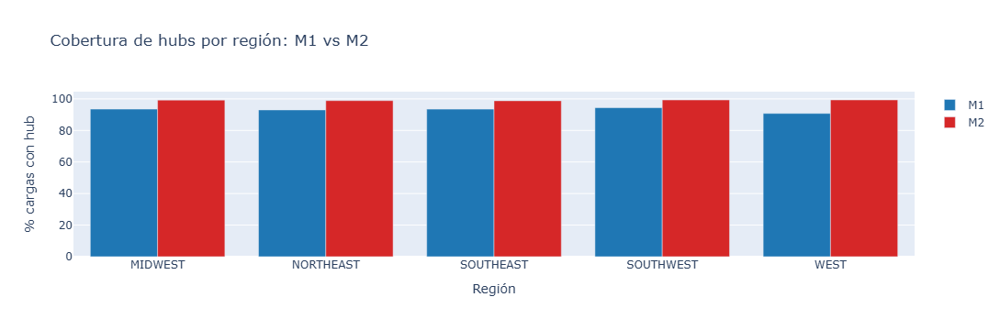

In [8]:
df['region'] = df['StateOrigin'].map(region5)
reg_cob = (
    df.groupby('region')
    .agg(
        total=('ID', 'count'),
        m1_hub=('hub_m1', 'sum'),
        m2_hub=('hub_m2', 'sum')
    )
    .assign(
        pct_m1=lambda x: 100 * x['m1_hub'] / x['total'],
        pct_m2=lambda x: 100 * x['m2_hub'] / x['total']
    )
    .reset_index()
    .dropna(subset=['region'])
)

fig_reg = go.Figure()
fig_reg.add_trace(go.Bar(x=reg_cob['region'], y=reg_cob['pct_m1'], name='M1', marker_color='#1f77b4'))
fig_reg.add_trace(go.Bar(x=reg_cob['region'], y=reg_cob['pct_m2'], name='M2', marker_color='#d62728'))
fig_reg.update_layout(
    barmode='group',
    title='Cobertura de hubs por región: M1 vs M2',
    yaxis_title='% cargas con hub',
    xaxis_title='Región'
)
fig_reg.show()

## 6. Comparación inbound/outbound ratio

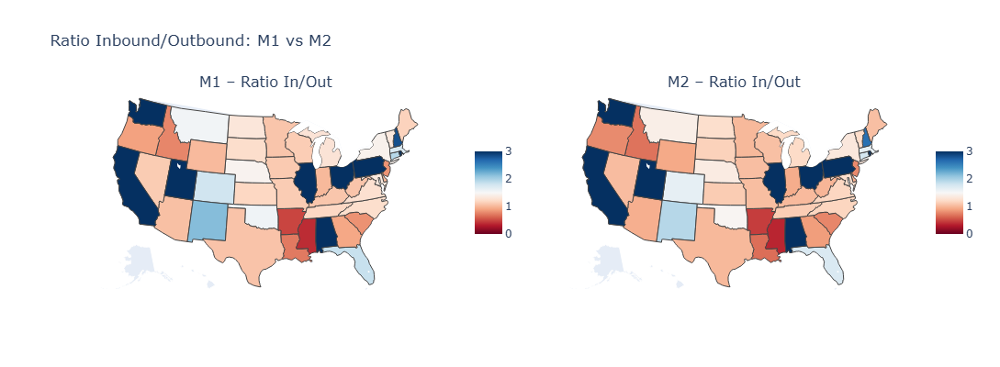

In [9]:
# M1: inbound = cargas con HubDestination asignado por estado
# M2: inbound = cargas con near_hub_dest_m2 asignado

# Para M1 — sin apply, usando filtro + groupby directo
m1_out = df.groupby('StateOrigin')['hub_m1'].sum().rename('out_m1')
m1_in  = df[df['HubDestination'].notna()].groupby('StateDestination')['ID'].count().rename('in_m1')

# Para M2
if 'near_hub_dest_m2' in df.columns:
    df['hub_dest_m2'] = df['near_hub_dest_m2'].notna()
    m2_out = df.groupby('StateOrigin')['hub_m2'].sum().rename('out_m2')
    m2_in  = df.groupby('StateDestination')['hub_dest_m2'].sum().rename('in_m2')
    io = pd.concat([m1_out, m1_in, m2_out, m2_in], axis=1).fillna(0).reset_index()
else:
    io = pd.concat([m1_out, m1_in], axis=1).fillna(0).reset_index()
    io['out_m2'] = 0; io['in_m2'] = 0

io.columns = ['state'] + list(io.columns[1:])
io['ratio_m1'] = io['in_m1'] / (io['out_m1'] + 1e-9)
io['ratio_m2'] = io['in_m2'] / (io['out_m2'] + 1e-9)

fig_io = make_subplots(rows=1, cols=2,
    subplot_titles=['M1 – Ratio In/Out', 'M2 – Ratio In/Out'],
    specs=[[{'type': 'choropleth'}, {'type': 'choropleth'}]])

for i, col in enumerate(['ratio_m1', 'ratio_m2'], 1):
    fig_io.add_trace(
        go.Choropleth(
            locations=io['state'], z=io[col],
            locationmode='USA-states',
            colorscale='RdBu', zmid=1.0, zmin=0, zmax=3,
            colorbar_x=0.46 if i==1 else 1.0,
            colorbar_len=0.5
        ), row=1, col=i
    )

fig_io.update_geos(scope='usa')
fig_io.update_layout(title='Ratio Inbound/Outbound: M1 vs M2', height=400)
fig_io.show()

## 7. Comparación Rate per Mile

RPM promedio M1: 2.65 | mediana: 2.27
RPM promedio M2: 3.04 | mediana: 2.25


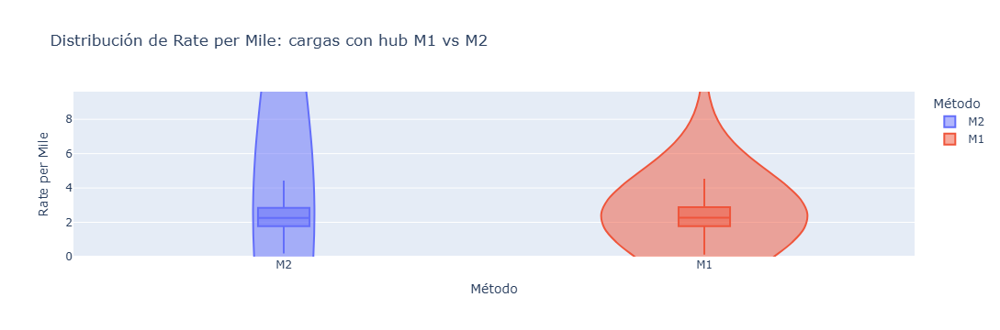

In [10]:
if 'RatePerMile' in df.columns:
    # Limpiar inf antes de calcular
    rpm_m1 = df[df['hub_m1']]['RatePerMile'].replace([np.inf, -np.inf], np.nan).dropna()
    rpm_m2 = df[df['hub_m2']]['RatePerMile'].replace([np.inf, -np.inf], np.nan).dropna()
    # Filtrar outliers extremos (> percentil 99.9)
    cap = max(rpm_m1.quantile(0.999), rpm_m2.quantile(0.999))
    rpm_m1 = rpm_m1[rpm_m1 <= cap]
    rpm_m2 = rpm_m2[rpm_m2 <= cap]

    rpm_df = pd.concat([
        pd.DataFrame({'rpm': rpm_m1, 'metodo': 'M1'}),
        pd.DataFrame({'rpm': rpm_m2, 'metodo': 'M2'})
    ])

    print(f'RPM promedio M1: {rpm_m1.mean():.2f} | mediana: {rpm_m1.median():.2f}')
    print(f'RPM promedio M2: {rpm_m2.mean():.2f} | mediana: {rpm_m2.median():.2f}')

    fig_rpm = px.violin(
        rpm_df.sample(min(100_000, len(rpm_df)), random_state=42),
        x='metodo', y='rpm', color='metodo',
        box=True, points=False,
        title='Distribución de Rate per Mile: cargas con hub M1 vs M2',
        labels={'rpm': 'Rate per Mile', 'metodo': 'Método'},
        range_y=[0, rpm_df['rpm'].quantile(0.99)]
    )
    fig_rpm.show()
    del rpm_m1, rpm_m2, rpm_df
    gc.collect()

## 8. Comparación de Deadhead (distancia carga → hub asignado)

In [11]:
n = len(df)

# Métricas de cobertura
cob_m1_global = 100 * df['hub_m1'].mean()
cob_m2_global = 100 * df['hub_m2'].mean()
r50_m1 = 100 * df['en_radio_50_m1'].mean()
r50_m2 = 100 * df['en_radio_50_m2'].mean()

# Eficiencia
cph_m1 = cargas_m1.mean() if 'cargas_m1' in dir() else None
cph_m2 = cargas_m2.mean() if 'cargas_m2' in dir() else None

# Deadhead — usa variables pre-calculadas (si ya corrieron las celdas de DH)
dh_m1_med_ = dh_m1_med if 'dh_m1_med' in dir() else None
dh_m2_med_ = dh_m2_med if 'dh_m2_med' in dir() else None
dh50_m1_   = dh50_m1   if 'dh50_m1'   in dir() else None
dh50_m2_   = dh50_m2   if 'dh50_m2'   in dir() else None

# Conectividad
fl_m1_top10_pct = 100*flujos_m1.head(10)['cargas'].sum()/flujos_m1['cargas'].sum() if 'flujos_m1' in dir() else None
fl_m2_top10_pct = 100*flujos_m2.head(10)['cargas'].sum()/flujos_m2['cargas'].sum() if 'flujos_m2' in dir() else None

# Distancia de cargas
dist_m1_med_ = dist_m1_med if 'dist_m1_med' in dir() else None
dist_m2_med_ = dist_m2_med if 'dist_m2_med' in dir() else None

def fmt(v, suffix='', fmt='.1f'):
    return f'{v:{fmt}}{suffix}' if v is not None else 'N/A'

resumen = pd.DataFrame([
    {'Dimensión': 'Total hubs',                       'M1': f'{len(hubs_m1):,}',          'M2': f'{len(hubs_m2):,}'},
    {'Dimensión': 'Hubs con nombre',                  'M1': f'{len(hubs_m1):,}',          'M2': f'{len(hubs_m2_named):,}'},
    {'Dimensión': '% cargas con hub asignado',        'M1': fmt(cob_m1_global, '%'),      'M2': fmt(cob_m2_global, '%')},
    {'Dimensión': '% cargas hub en 50 millas',        'M1': fmt(r50_m1, '%'),             'M2': fmt(r50_m2, '%')},
    {'Dimensión': 'Cargas promedio por hub',          'M1': fmt(cph_m1, '', ',.0f'),      'M2': fmt(cph_m2, '', ',.0f')},
    {'Dimensión': '% hubs M2 solapados M1 (50mi)',    'M1': '—',                          'M2': fmt(100*solapados/total_m2, '%') if 'solapados' in dir() else 'N/A'},
    {'Dimensión': 'Deadhead mediano',                 'M1': fmt(dh_m1_med_, ' mi'),       'M2': fmt(dh_m2_med_, ' mi')},
    {'Dimensión': '% cargas con DH ≤ 50mi',          'M1': fmt(dh50_m1_, '%'),           'M2': fmt(dh50_m2_, '%')},
    {'Dimensión': 'Pares hub-hub con flujo',          'M1': fmt(len(flujos_m1), '', ',d') if 'flujos_m1' in dir() else 'N/A',
                                                       'M2': fmt(len(flujos_m2), '', ',d') if 'flujos_m2' in dir() else 'N/A'},
    {'Dimensión': '% cargas en top-10 flujos',        'M1': fmt(fl_m1_top10_pct, '%'),    'M2': fmt(fl_m2_top10_pct, '%')},
    {'Dimensión': 'Distancia mediana de cargas',      'M1': fmt(dist_m1_med_, ' mi'),     'M2': fmt(dist_m2_med_, ' mi')},
])

print('\n=== RESUMEN EJECUTIVO ===')
print(resumen.to_string(index=False))


=== RESUMEN EJECUTIVO ===
                    Dimensión      M1      M2
                   Total hubs     194     192
              Hubs con nombre     194      88
    % cargas con hub asignado   93.2%   99.1%
    % cargas hub en 50 millas   93.2%    0.0%
      Cargas promedio por hub 177,661 559,276
% hubs M2 solapados M1 (50mi)       —   68.2%
             Deadhead mediano     N/A     N/A
       % cargas con DH ≤ 50mi     N/A     N/A
      Pares hub-hub con flujo     N/A     N/A
    % cargas en top-10 flujos     N/A     N/A
  Distancia mediana de cargas     N/A     N/A


In [12]:
# Deadhead M1 — vectorizado, sin copiar el df completo (57M filas)
_hub_lat = (hubs_m1.dropna(subset=['lat','lng'])
            .drop_duplicates(subset=['new_name'])
            .set_index('new_name')['lat'])
_hub_lng = (hubs_m1.dropna(subset=['lat','lng'])
            .drop_duplicates(subset=['new_name'])
            .set_index('new_name')['lng'])

_mask = df['HubOrigin'].notna() & df['LatOrigin'].notna()
_lat_o = df.loc[_mask, 'LatOrigin'].astype(float).values
_lng_o = df.loc[_mask, 'LngOrigin'].astype(float).values
_lat_h = _hub_lat.reindex(df.loc[_mask, 'HubOrigin']).values
_lng_h = _hub_lng.reindex(df.loc[_mask, 'HubOrigin']).values

_dlat = np.radians(_lat_h - _lat_o)
_dlng = np.radians(_lng_h - _lng_o)
_a = np.sin(_dlat/2)**2 + np.cos(np.radians(_lat_o)) * np.cos(np.radians(_lat_h)) * np.sin(_dlng/2)**2
_dh = 3958.8 * 2 * np.arctan2(np.sqrt(_a), np.sqrt(1 - _a))

dh_m1_med = float(np.nanmedian(_dh))
dh50_m1   = float(100 * np.nanmean(_dh <= 50))
print(f'Deadhead M1: mediana {dh_m1_med:.1f} mi | promedio {np.nanmean(_dh):.1f} mi')
print(f'% cargas M1 con DH ≤ 50mi: {dh50_m1:.1f}%')

_idx = np.random.default_rng(42).choice(len(_dh), min(200_000, len(_dh)), replace=False)
dh_m1_sample = _dh[_idx]
del _lat_o, _lng_o, _lat_h, _lng_h, _dlat, _dlng, _a, _dh, _idx, _hub_lat, _hub_lng, _mask
gc.collect()

Deadhead M1: mediana 32.3 mi | promedio 33.7 mi
% cargas M1 con DH ≤ 50mi: 80.4%


0

In [ ]:
# Deadhead M2 — vectorizado, sin copiar el df completo
# FIX BUG 3: hubs_m2_raw usa id.astype(str) que produce 'nan' para terciarios
# (id=NaN en el CSV), pero near_hub_m2 los almacena como 'C6', 'C16', etc.
# Reconstruir lookup con el mismo esquema de IDs que genera 1_assign_hubs_m2.ipynb.
_rows_m2 = []
for _, _r in hubs_m2_raw.dropna(subset=['lat', 'lng']).iterrows():
    if pd.notna(_r.get('new_name')):           # primaria o secundaria
        _hid = str(_r['id'])
    else:                                       # terciario: hub_id = 'C<cluster>'
        _hid = f'C{int(_r["cluster"])}' if pd.notna(_r.get('cluster')) else None
    if _hid is not None:
        _rows_m2.append({'_hid': _hid, 'lat': _r['lat'], 'lng': _r['lng']})
_hub_m2_lookup = pd.DataFrame(_rows_m2).drop_duplicates(subset=['_hid']).set_index('_hid')
_hub_lat_m2 = _hub_m2_lookup['lat']
_hub_lng_m2 = _hub_m2_lookup['lng']
del _rows_m2, _hub_m2_lookup

_mask = df['near_hub_m2'].notna() & df['LatOrigin'].notna()
_lat_o = df.loc[_mask, 'LatOrigin'].astype(float).values
_lng_o = df.loc[_mask, 'LngOrigin'].astype(float).values
_lat_h = _hub_lat_m2.reindex(df.loc[_mask, 'near_hub_m2']).values
_lng_h = _hub_lng_m2.reindex(df.loc[_mask, 'near_hub_m2']).values

_dlat = np.radians(_lat_h - _lat_o)
_dlng = np.radians(_lng_h - _lng_o)
_a = np.sin(_dlat/2)**2 + np.cos(np.radians(_lat_o)) * np.cos(np.radians(_lat_h)) * np.sin(_dlng/2)**2
_dh = 3958.8 * 2 * np.arctan2(np.sqrt(_a), np.sqrt(1 - _a))

dh_m2_med = float(np.nanmedian(_dh))
dh50_m2   = float(100 * np.nanmean(_dh <= 50))
print(f'Deadhead M2: mediana {dh_m2_med:.1f} mi | promedio {np.nanmean(_dh):.1f} mi')
print(f'% cargas M2 con DH ≤ 50mi: {dh50_m2:.1f}%')

_idx = np.random.default_rng(42).choice(len(_dh), min(200_000, len(_dh)), replace=False)
dh_m2_sample = _dh[_idx]
del _lat_o, _lng_o, _lat_h, _lng_h, _dlat, _dlng, _a, _dh, _idx, _hub_lat_m2, _hub_lng_m2, _mask
gc.collect()


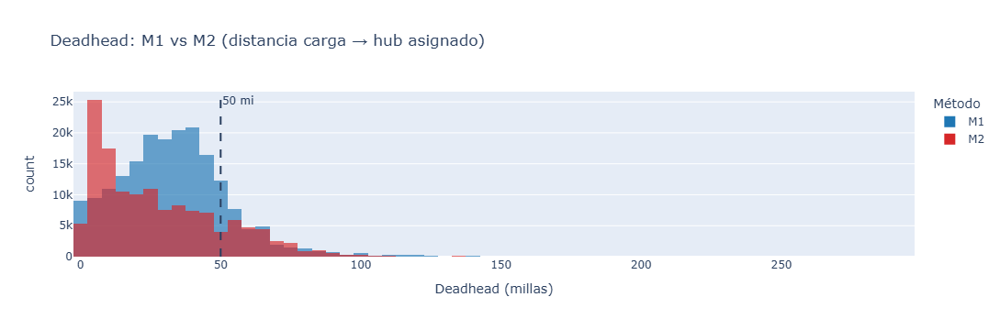

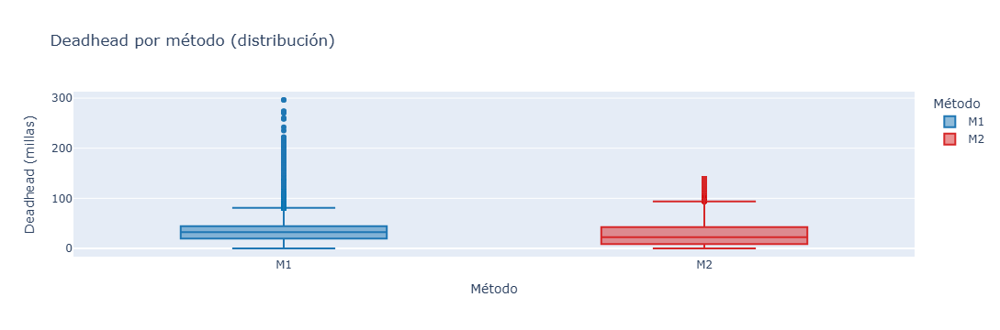

306

In [14]:
# Histograma comparativo de deadhead — usa muestras (200k), no el df completo
dh_comp = pd.DataFrame({
    'deadhead': np.concatenate([dh_m1_sample, dh_m2_sample]),
    'metodo': ['M1'] * len(dh_m1_sample) + ['M2'] * len(dh_m2_sample)
})

fig_dh = px.histogram(
    dh_comp[dh_comp['deadhead'] <= 300],
    x='deadhead', color='metodo', nbins=60, barmode='overlay',
    opacity=0.65,
    title='Deadhead: M1 vs M2 (distancia carga → hub asignado)',
    labels={'deadhead': 'Deadhead (millas)', 'count': 'N cargas', 'metodo': 'Método'},
    color_discrete_map={'M1': '#1f77b4', 'M2': '#d62728'}
)
fig_dh.add_vline(x=50, line_dash='dash', annotation_text='50 mi')
fig_dh.show()

fig_dh_box = px.box(
    dh_comp[dh_comp['deadhead'] <= 300],
    x='metodo', y='deadhead', color='metodo',
    title='Deadhead por método (distribución)',
    labels={'deadhead': 'Deadhead (millas)', 'metodo': 'Método'},
    color_discrete_map={'M1': '#1f77b4', 'M2': '#d62728'}
)
fig_dh_box.show()
del dh_comp
gc.collect()

## 9. Comparación de Conectividad (flujos entre hubs)

In [15]:
# Flujos M1
flujos_m1 = (
    df[df['HubOrigin'].notna() & df['HubDestination'].notna()]
    .groupby(['HubOrigin', 'HubDestination'])['ID'].count()
    .reset_index()
    .rename(columns={'ID': 'cargas', 'HubOrigin': 'origen', 'HubDestination': 'destino'})
    .sort_values('cargas', ascending=False)
)

# Flujos M2
flujos_m2 = (
    df[df['near_hub_name_m2'].notna() & df['near_hub_dest_m2'].notna()]
    .groupby(['near_hub_name_m2', 'near_hub_dest_m2'])['ID'].count()
    .reset_index()
    .rename(columns={'ID': 'cargas', 'near_hub_name_m2': 'origen', 'near_hub_dest_m2': 'destino'})
    .sort_values('cargas', ascending=False)
)

print(f'Pares de hubs con flujo – M1: {len(flujos_m1):,} | M2: {len(flujos_m2):,}')
print(f'Concentración top-10 M1: {100*flujos_m1.head(10)["cargas"].sum()/flujos_m1["cargas"].sum():.1f}% de cargas')
print(f'Concentración top-10 M2: {100*flujos_m2.head(10)["cargas"].sum()/flujos_m2["cargas"].sum():.1f}% de cargas')

Pares de hubs con flujo – M1: 55,534 | M2: 7,034
Concentración top-10 M1: 1.7% de cargas
Concentración top-10 M2: 3.2% de cargas


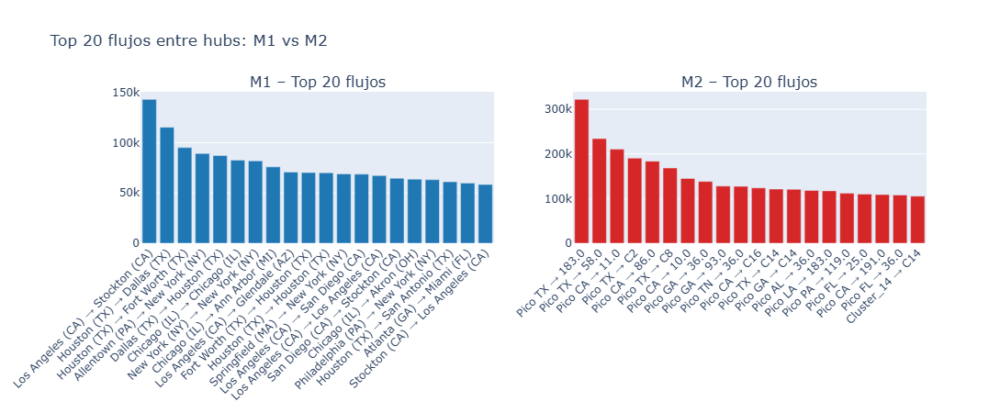

In [16]:
# Top 20 flujos lado a lado
fl_m1_top = flujos_m1.head(20).copy()
fl_m1_top['par'] = fl_m1_top['origen'].astype(str) + ' → ' + fl_m1_top['destino'].astype(str)
fl_m1_top['metodo'] = 'M1'

fl_m2_top = flujos_m2.head(20).copy()
fl_m2_top['par'] = fl_m2_top['origen'].astype(str) + ' → ' + fl_m2_top['destino'].astype(str)
fl_m2_top['metodo'] = 'M2'

fig_fl = make_subplots(rows=1, cols=2, subplot_titles=['M1 – Top 20 flujos', 'M2 – Top 20 flujos'])
fig_fl.add_trace(
    go.Bar(x=fl_m1_top['par'], y=fl_m1_top['cargas'], name='M1', marker_color='#1f77b4'),
    row=1, col=1
)
fig_fl.add_trace(
    go.Bar(x=fl_m2_top['par'], y=fl_m2_top['cargas'], name='M2', marker_color='#d62728'),
    row=1, col=2
)
fig_fl.update_layout(
    title='Top 20 flujos entre hubs: M1 vs M2',
    height=450, showlegend=False
)
fig_fl.update_xaxes(tickangle=-45)
fig_fl.show()

## 10. Comparación de Distancia de Cargas

Distancia promedio M1: 728 mi | mediana: 569 mi
Distancia promedio M2: 730 mi | mediana: 569 mi


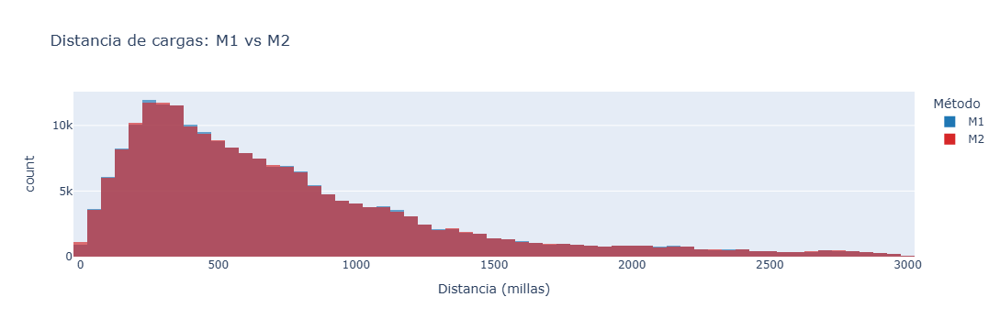

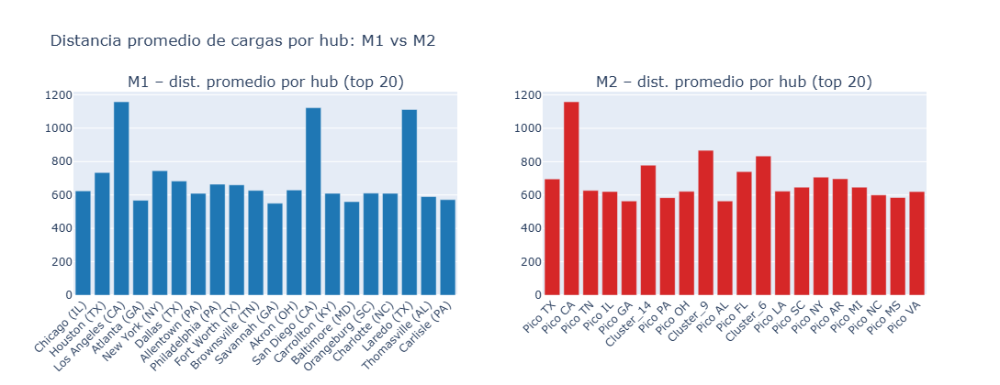

In [17]:
if 'Distance' in df.columns:
    dist_m1 = df[df['hub_m1']]['Distance'].dropna()
    dist_m2 = df[df['hub_m2']]['Distance'].dropna()

    dist_m1_med = float(dist_m1.median())
    dist_m2_med = float(dist_m2.median())
    print(f"Distancia promedio M1: {dist_m1.mean():.0f} mi | mediana: {dist_m1_med:.0f} mi")
    print(f"Distancia promedio M2: {dist_m2.mean():.0f} mi | mediana: {dist_m2_med:.0f} mi")

    # Muestra 200k por método para el histograma
    n_samp = 200_000
    dist_df = pd.concat([
        dist_m1.sample(min(n_samp, len(dist_m1)), random_state=42)
               .rename('distancia').to_frame().assign(metodo='M1'),
        dist_m2.sample(min(n_samp, len(dist_m2)), random_state=42)
               .rename('distancia').to_frame().assign(metodo='M2')
    ])
    del dist_m1, dist_m2

    fig_dist = px.histogram(
        dist_df[dist_df['distancia'] < 3000],
        x='distancia', color='metodo', nbins=80, barmode='overlay',
        opacity=0.65,
        title='Distancia de cargas: M1 vs M2',
        labels={'distancia': 'Distancia (millas)', 'count': 'N cargas', 'metodo': 'Método'},
        color_discrete_map={'M1': '#1f77b4', 'M2': '#d62728'}
    )
    fig_dist.show()
    del dist_df
    gc.collect()

    # Distancia promedio por hub top 20 – M1 vs M2
    dist_hub_m1 = (
        df[df['HubOrigin'].notna()]
        .groupby('HubOrigin')['Distance']
        .agg(dist_mean='mean', n='count')
        .reset_index().rename(columns={'HubOrigin': 'hub'})
        .sort_values('n', ascending=False).head(20)
        .assign(metodo='M1')
    )
    dist_hub_m2 = (
        df[df['near_hub_name_m2'].notna()]
        .groupby('near_hub_name_m2')['Distance']
        .agg(dist_mean='mean', n='count')
        .reset_index().rename(columns={'near_hub_name_m2': 'hub'})
        .sort_values('n', ascending=False).head(20)
        .assign(metodo='M2')
    )

    fig_dist_hub = make_subplots(rows=1, cols=2,
        subplot_titles=['M1 – dist. promedio por hub (top 20)', 'M2 – dist. promedio por hub (top 20)'])
    fig_dist_hub.add_trace(
        go.Bar(x=dist_hub_m1['hub'], y=dist_hub_m1['dist_mean'],
               marker_color='#1f77b4', name='M1'), row=1, col=1)
    fig_dist_hub.add_trace(
        go.Bar(x=dist_hub_m2['hub'], y=dist_hub_m2['dist_mean'],
               marker_color='#d62728', name='M2'), row=1, col=2)
    fig_dist_hub.update_layout(title='Distancia promedio de cargas por hub: M1 vs M2',
                                height=420, showlegend=False)
    fig_dist_hub.update_xaxes(tickangle=-45)
    fig_dist_hub.show()
    del dist_hub_m1, dist_hub_m2
    gc.collect()

## 8. Tabla resumen ejecutivo

In [18]:
n = len(df)
cob_m1_global = 100 * df['hub_m1'].mean()
cob_m2_global = 100 * df['hub_m2'].mean()
r50_m1 = 100 * df['en_radio_50_m1'].mean()
r50_m2 = 100 * df['en_radio_50_m2'].mean()

cargas_por_hub_m1 = cargas_m1.mean() if 'cargas_m1' in dir() else None
cargas_por_hub_m2 = cargas_m2.mean() if 'cargas_m2' in dir() else None

resumen = pd.DataFrame([
    {'Dimensión': 'Total hubs',                    'M1': f'{len(hubs_m1):,}',           'M2': f'{len(hubs_m2):,}'},
    {'Dimensión': 'Hubs con nombre',               'M1': f'{len(hubs_m1):,}',           'M2': f'{len(hubs_m2_named):,}'},
    {'Dimensión': '% cargas con hub asignado',     'M1': f'{cob_m1_global:.1f}%',       'M2': f'{cob_m2_global:.1f}%'},
    {'Dimensión': '% cargas hub en 50 millas',     'M1': f'{r50_m1:.1f}%',              'M2': f'{r50_m2:.1f}%'},
    {'Dimensión': 'Cargas promedio por hub',
     'M1': f'{cargas_por_hub_m1:,.0f}' if cargas_por_hub_m1 is not None else 'N/A',
     'M2': f'{cargas_por_hub_m2:,.0f}' if cargas_por_hub_m2 is not None else 'N/A'},
    {'Dimensión': '% hubs M2 solapados con M1 (50mi)',
     'M1': '—',
     'M2': f'{100*solapados/total_m2:.1f}%' if 'solapados' in dir() else 'N/A'},
    {'Dimensión': 'Deadhead mediano',
     'M1': f'{dh_m1_med:.1f} mi' if 'dh_m1_med' in dir() else 'N/A',
     'M2': f'{dh_m2_med:.1f} mi' if 'dh_m2_med' in dir() else 'N/A'},
    {'Dimensión': '% cargas con DH ≤ 50mi',
     'M1': f'{dh50_m1:.1f}%' if 'dh50_m1' in dir() else 'N/A',
     'M2': f'{dh50_m2:.1f}%' if 'dh50_m2' in dir() else 'N/A'},
    {'Dimensión': 'Distancia mediana de cargas',
     'M1': f'{dist_m1_med:.0f} mi' if 'dist_m1_med' in dir() else 'N/A',
     'M2': f'{dist_m2_med:.0f} mi' if 'dist_m2_med' in dir() else 'N/A'},
])

print('\n=== RESUMEN EJECUTIVO ===')
print(resumen.to_string(index=False))


=== RESUMEN EJECUTIVO ===
                        Dimensión      M1      M2
                       Total hubs     194     192
                  Hubs con nombre     194      88
        % cargas con hub asignado   93.2%   99.1%
        % cargas hub en 50 millas   93.2%    0.0%
          Cargas promedio por hub 177,661 559,276
% hubs M2 solapados con M1 (50mi)       —   68.2%
                 Deadhead mediano 32.3 mi 24.7 mi
           % cargas con DH ≤ 50mi   80.4%   55.9%
      Distancia mediana de cargas  569 mi  569 mi
